# TITANIC EXPLORATORY DATA ANALYSIS (EDA)

Project Objective:

The goal of this project is to explore the Titanic passenger dataset,
     understand its data quality, analyze passenger characteristics,
     and investigate patterns associated with passenger survival.

This project uses Python, NumPy, Pandas, and Matplotlib.

In [210]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 

# PART 1: DATA UNDERSTANDING & CLEANING

## 1.1 LOADING THE DATASET

First, we load the Titanic dataset into a Pandas DataFrame.

In [211]:
df = pd.read_csv("titanic.csv")
print("Dataset loaded successfully!!!")

Dataset loaded successfully!!!


## 1.2 INITIAL DATASET PREVIEW

We inspect the first and last few records to understand how the data is organized.

In [212]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [213]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


## 1.3 DATASET DIMENSIONS

We determine the total number of passenger records and features.

In [214]:
rows, columns = df.shape
print("Total Rows: ", rows)
print("Total Columns: ", columns)

Total Rows:  891
Total Columns:  15


## 1.4 COLUMN NAMES

We list all columns to identify the information available for analysis.

In [215]:
print(df.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


## 1.5 DATA TYPES AND NON-MISSING VALUES

We inspect the data type of each column and the number of missing values.

In [216]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


## 1.6 UNDERSTANDING THE FEATURES

The dataset contains information about Titanic passengers, including their survival status, passenger class, demographic information, family information, fare, embarkation details, and cabin/deck information.

The following table describes the main features available in this dataset.

| Column | Description |
|---|---|
| `survived` | Survival status: 0 = No, 1 = Yes |
| `pclass` | Passenger class: 1, 2, or 3 |
| `sex` | Passenger gender |
| `age` | Passenger age |
| `sibsp` | Number of siblings/spouses aboard |
| `parch` | Number of parents/children aboard |
| `fare` | Passenger fare |
| `embarked` | Port of embarkation: C, Q, S |
| `class` | Passenger class as text |
| `who` | Passenger category: man, woman, child |
| `adult_male` | Whether the passenger is an adult male |
| `deck` | Passenger deck |
| `embark_town` | Full name of embarkation town |
| `alive` | Survival status as yes/no |
| `alone` | Whether the passenger was travelling alone |

## 1.7 NUMERICAL AND CATEGORICAL FEATURES

We classify the features according to their analytical role rather than relying only on their storage data types.
Some columns are stored as numbers but represent categories. For example, `survived` and `pclass`.

In [217]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [218]:
numerical_columns = ["age", "fare", "sibsp", "parch"]
categorical_columns = ["survived", "pclass", "sex", "embarked", "class", "who", "adult_male", "deck", "embark_town", "alive", "alone"]

In [219]:
print("NUMERICAL COLUMNS: ")
print(numerical_columns)
print("\nCATEGORICAL COLUMNS: ")
print(categorical_columns)

NUMERICAL COLUMNS: 
['age', 'fare', 'sibsp', 'parch']

CATEGORICAL COLUMNS: 
['survived', 'pclass', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


## 1.8 STATISTICAL SUMMARY

We examine the statistical properties of the numerical features, such as count, mean, standard deviation, minimum, maximum, and quartiles.

In [220]:
df[numerical_columns].describe()

,age,fare,sibsp,parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


In [221]:
df.describe(include = "all")

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.9 CATEGORICAL FREQUENCY ANALYSIS

We examine the frequency distribution of categorical features to understand the number of observations in each category.
Missing values are also included in the count.



In [222]:
for column in categorical_columns:
    print(f"==== {column} ====")
    print(df[column].value_counts(dropna = False))
    print("\n")

==== survived ====
survived
0    549
1    342
Name: count, dtype: int64


==== pclass ====
pclass
3    491
1    216
2    184
Name: count, dtype: int64


==== sex ====
sex
male      577
female    314
Name: count, dtype: int64


==== embarked ====
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


==== class ====
class
Third     491
First     216
Second    184
Name: count, dtype: int64


==== who ====
who
man      537
woman    271
child     83
Name: count, dtype: int64


==== adult_male ====
adult_male
True     537
False    354
Name: count, dtype: int64


==== deck ====
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64


==== embark_town ====
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64


==== alive ====
alive
no     549
yes    342
Name: count, dtype: int64


==== alone ====
alone
True     537
False    354
Name: count, dty

## 1.10 MISSING VALUES ANALYSIS

We identify the missing values in each column and calculate their percentage.
Understanding missing data is important before deciding whether to remove or replace missing values.

In [223]:
missing_count = df.isnull().sum()
print("MISSING COUNT")
print("\n")
print(missing_count)

MISSING COUNT


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [224]:
missing_percentage = (missing_count/len(df))*100
print("MISSING PERCENTAGE: ")
print("\n")
print(missing_percentage)

MISSING PERCENTAGE: 


survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [225]:
missing_summary = pd.DataFrame(
    {
        "Missing Count" : missing_count, 
        "Missing Percentage" : missing_percentage
    }
)

print(missing_summary)

             Missing Count  Missing Percentage
survived                 0            0.000000
pclass                   0            0.000000
sex                      0            0.000000
age                    177           19.865320
sibsp                    0            0.000000
parch                    0            0.000000
fare                     0            0.000000
embarked                 2            0.224467
class                    0            0.000000
who                      0            0.000000
adult_male               0            0.000000
deck                   688           77.216611
embark_town              2            0.224467
alive                    0            0.000000
alone                    0            0.000000


In [226]:
missing_summary = missing_summary.sort_values(by = "Missing Percentage", ascending = False)

print(missing_summary)

             Missing Count  Missing Percentage
deck                   688           77.216611
age                    177           19.865320
embarked                 2            0.224467
embark_town              2            0.224467
sex                      0            0.000000
pclass                   0            0.000000
survived                 0            0.000000
fare                     0            0.000000
parch                    0            0.000000
sibsp                    0            0.000000
class                    0            0.000000
adult_male               0            0.000000
who                      0            0.000000
alive                    0            0.000000
alone                    0            0.000000


In [227]:
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
print(missing_summary)

             Missing Count  Missing Percentage
deck                   688           77.216611
age                    177           19.865320
embarked                 2            0.224467
embark_town              2            0.224467


## 1.11 DUPLICATE ANALYSIS

We check for extra duplicate rows in the dataset.
However, this dataset does not contain a unique passenger identifier. Therefore, an identical row does not necessarily mean that the same passenger has been duplicated.

For this reason, duplicate rows will be investigated but not automatically removed.

In [228]:
duplicate_count = df.duplicated().sum()
print("Number of exact duplicate rows: ", duplicate_count)

Number of exact duplicate rows:  107


## 1.12 INVALID AND SUSPICIOUS VALUES

Examples include negative age values, negative fare values, invalid survival values, invalid passenger class values, and unexpected categories.

In [229]:
print("Negative Age: ", (df["age"] < 0).sum())
print("Negative Fare: ", (df["fare"] < 0).sum())

Negative Age:  0
Negative Fare:  0


In [310]:
print("\nAGE GREATER THAN 100: ")
print(df.loc[df["age"] > 100, ["age"]])


AGE GREATER THAN 100: 
Empty DataFrame
Columns: [age]
Index: []


In [231]:
print("\nZERO FARE: ")
print(df.loc[df["fare"] == 0, ["pclass", "fare"]])


ZERO FARE: 
     pclass  fare
179       3   0.0
263       1   0.0
271       3   0.0
277       2   0.0
302       3   0.0
413       2   0.0
466       2   0.0
481       2   0.0
597       3   0.0
633       1   0.0
674       2   0.0
732       2   0.0
806       1   0.0
815       1   0.0
822       1   0.0


In [232]:
print("\nUNEXPECTED SURVIVAL VALUES: ")
print(
    df.loc[
        ~df["survived"].isin([0, 1]),
        ["survived"]
    ].drop_duplicates()
)


UNEXPECTED SURVIVAL VALUES: 
Empty DataFrame
Columns: [survived]
Index: []


In [233]:
print("\nUNEXPECTED PCLASS VALUES: ")
print(
    df.loc[
        ~df["pclass"].isin([1, 2, 3]),
        ["pclass"]
    ].drop_duplicates()
)


UNEXPECTED PCLASS VALUES: 
Empty DataFrame
Columns: [pclass]
Index: []


In [234]:
print("\nUNEXPECTED EMBARKED VALUES: ")
print(
    df.loc[
        ~df["embarked"].isin(["C", "Q", "S"]) & df["embarked"].notna(), ["embarked"]
    ].drop_duplicates()
)


UNEXPECTED EMBARKED VALUES: 
Empty DataFrame
Columns: [embarked]
Index: []


## 1.13 MISSING VALUES HANDLING 

After identifying missing values, we decide how to handle them.

We will not blindly remove rows or replace all missing values.

- `age` contains a substantial number of missing values, so we will preserve them for EDA and handle them according to the analysis.

- `deck` contains a large number of missing values, so these missing values will be preserved.

- `embarked` contains only a few missing values and can be filled using the mode.

- `embark_town` will be kept consistent with `embarked`.

In [235]:
df_clean = df.copy()

In [236]:
print("ORIGINAL SHAPE: ", df.shape)
print("CLEANED SHAPE: ", df_clean.shape)

ORIGINAL SHAPE:  (891, 15)
CLEANED SHAPE:  (891, 15)


In [237]:
embarked_mode = df_clean["embarked"].mode()[0]
df_clean["embarked"] = df_clean["embarked"].fillna(embarked_mode)

print("\nMISSING EMBARKED VALUES: ", df_clean["embarked"].isnull().sum())


MISSING EMBARKED VALUES:  0


In [238]:
embark_town_mapping = {
    "S": "Southampton",
    "C": "Cherbourg",
    "Q": "Queenstown"
}

df_clean["embark_town"] = df_clean["embarked"].map(embark_town_mapping)

print("Missing embark_town values:",
    df_clean["embark_town"].isnull().sum())

Missing embark_town values: 0


The two missing `embarked` values are imputed using the most frequent embarkation port (mode). This affects only a very small number of records.

## 1.14 ORIGINAL VS CLEANED DATASET

We compare the original and cleaned dataset to verify the effect of our cleaning operations.

In [314]:
comparison = pd.DataFrame(
    {
        "BEFORE CLEANING" : df.isnull().sum(), 
        "AFTER CLEANING" : df_clean.isnull().sum()
    }
)
comparison

,BEFORE CLEANING,AFTER CLEANING
survived,0,0
pclass,0,0
sex,0,0
age,177,177
sibsp,0,0
parch,0,0
fare,0,0
embarked,2,0
class,0,0
who,0,0


In [240]:
print("ORIGINAL SHAPE: ", df.shape)
print("CLEANED SHAPE: ", df_clean.shape)

ORIGINAL SHAPE:  (891, 15)
CLEANED SHAPE:  (891, 15)


## 1.15 FINAL DATA QUALITY CHECK

Finally, we verify the cleaned dataset by checking its shape, data types, missing values, duplicate rows, and sample records.

The cleaned dataset will be used for the next stage of exploratory data analysis.

In [241]:
print("\nDATASET SHAPE: ")
print(df_clean.shape)

print("\nDATA TYPES: ")
print(df_clean.dtypes)

print("\nMISSING VALUES: ")
print(df_clean.isnull().sum())

print("\nTOTAL MISSING VALUES: ")
print(df_clean.isnull().sum().sum())

print("\nDUPLICATE ROWS: ")
print(df_clean.duplicated().sum())


DATASET SHAPE: 
(891, 15)

DATA TYPES: 
survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

MISSING VALUES: 
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64

TOTAL MISSING VALUES: 
865

DUPLICATE ROWS: 
107


In [242]:
print("\nFIRST 5 ROWS: ")
display(df_clean.head())


FIRST 5 ROWS: 


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# PART 1 SUMMARY

The Titanic dataset contains 891 passenger records and 15 features.

The dataset contains missing values in `age`, `deck`, `embarked`, and `embark_town`.

The missing values in `embarked` and `embark_town` were handled using the most frequent embarkation category.

Exact duplicate rows were identified, but they were not automatically removed because the dataset does not contain a unique passenger identifier.

The dataset is now ready for exploratory data analysis.

# PART 2: UNIVARIATE ANALYSIS

Univariate analysis focuses on understanding one feature at a time.

In this section, we will study the distribution, frequency, central tendency, spread, and possible outliers of important Titanic features.

## 2.1 THE MAIN FEATURES ANALYZED ARE

- `Survival status`

- `Gender`

- `Passenger class`

- `Age`

- `Fare`

- `Embarkation port`

- `Number of siblings/spouses`

- `Number of parents/children`

At this stage, we will focus on individual feature distributions and will not study relationships between features.

## 2.2 SURVIVAL STATUS

We examine the overall distribution of passenger survival status.

The `survived` column contains:
- `0` → Did not survive

- `1` → Survived

A bar chart will help you compare the number of survivors and non-survivors.

In [243]:
survival_counts = df_clean["survived"].value_counts().sort_index()
print(survival_counts)

survived
0    549
1    342
Name: count, dtype: int64


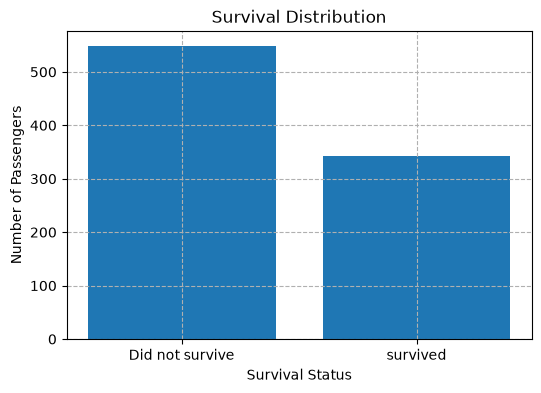

In [313]:
plt.figure(figsize = (6, 4))
plt.bar(["Did not survive", "survived"], survival_counts.values)

plt.title("Survival Distribution")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

The dataset contains more non-survivors than survivors. Therefore, survival was not evenly distributed among the passengers.

## 2.3 GENDER DISTRIBUTION

We analyze the distribution of passengers by their gender. This helps us understand the demographic composition of the Titanic passenger dataset.

In [245]:
sex_counts = df_clean["sex"].value_counts()
print(sex_counts)

sex
male      577
female    314
Name: count, dtype: int64


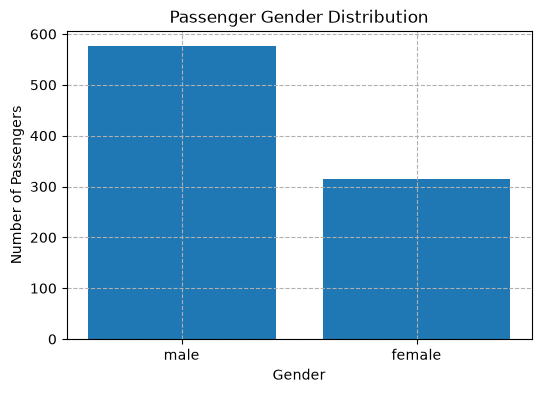

In [246]:
plt.figure(figsize = (6, 4))
plt.bar(sex_counts.index, sex_counts.values)

plt.title("Passenger Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

The dataset contains passengers from both male and female groups, with males representing the larger group.

## 2.4 PASSENGER CLASS DISTRIBUTION

We examine the distribution of the passengers across three different passenger classes.

The `pclass` feature represents:

- `1` → First Class

- `2` → Second Class

- `3` → Third Class

In [247]:
class_counts = df_clean["pclass"].value_counts().sort_index()
print(class_counts)

pclass
1    216
2    184
3    491
Name: count, dtype: int64


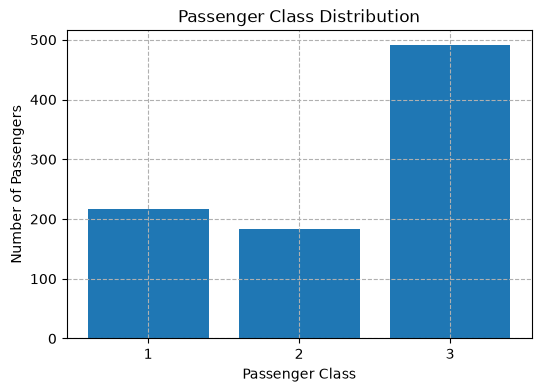

In [248]:
plt.figure(figsize = (6, 4))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.title("Passenger Class Distribution")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Third-class passengers form the largest group in the dataset, followed by first-class and second-class passengers.

## 2.5 AGE DISTRIBUTION

We analyse the age distribution of the passengers using a histogram.

The histogram helps us understand:
- The most common age ranges
- The spread of ages
- The shape of the distribution
- Possible concentration or skewness

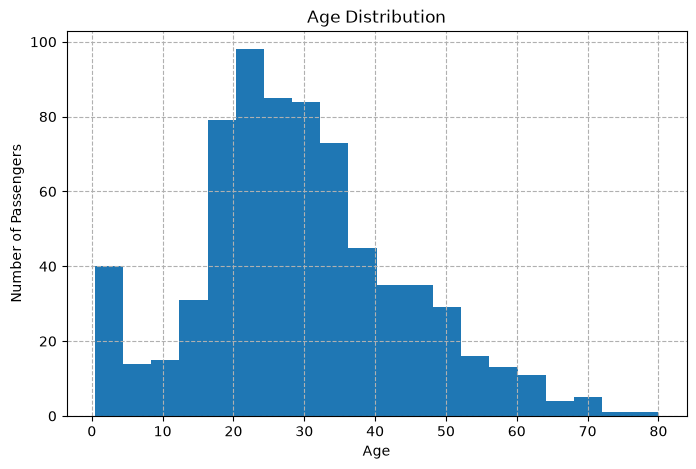

In [249]:
age_data = df_clean["age"].dropna()
plt.figure(figsize = (8, 5))

plt.hist(age_data, bins = 20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()


## 2.6 AGE STATISTICAL SUMMARY

We calculate descriptive statistics for passenger age to understand its central tendency and spread.

In [250]:
df_clean["age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64

### OBSERVATION

The average passenger age is approximately 30 years, while the median age is around 28 years. The distribution is concentrated around young and middle adulthood, with fewer elderly passengers.

## 2.7 FARE DISTRIBUTION

We analyze the distribution of passenger ticket fares.

A histogram helps us understand the concentration, spread and skewness of the fare values.

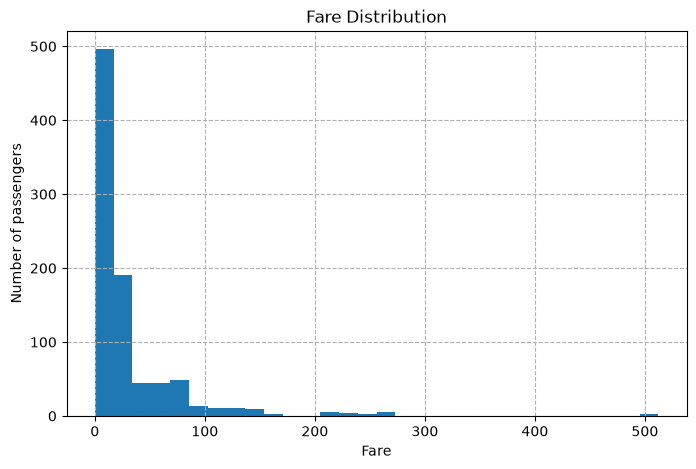

In [251]:
plt.figure(figsize = (8, 5))

plt.hist(df_clean["fare"], bins = 30)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of passengers")

plt.grid(linestyle = "--")
plt.show()

## 2.8 FARE STATISTICAL SUMMARY

We examine the descriptive statistics of the fare feature to understand its central tendency, spread, and range.

In [252]:
df_clean["fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

In [253]:
print("\nMEAN FARE: ", df_clean["fare"].mean())
print("\nMEDIAN FARE: ", df_clean["fare"].median())


MEAN FARE:  32.204207968574636

MEDIAN FARE:  14.4542


### OBSERVATION

Fare distribution is highly concentrated towards lower values, while a smaller number of passengers paid substantially high fares. This creates a right-skewed distribution.

## 2.9 EMBARKATION PORT DISTRIBUTION

The `embarked` column contains: 
- `S` → Southampton

- `C` → Cherbourg

- `Q` → Queenstown

In [254]:
embarked_counts = df_clean["embarked"].value_counts().sort_values()
port_names = {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}

embarked_counts

embarked
Q     77
C    168
S    646
Name: count, dtype: int64

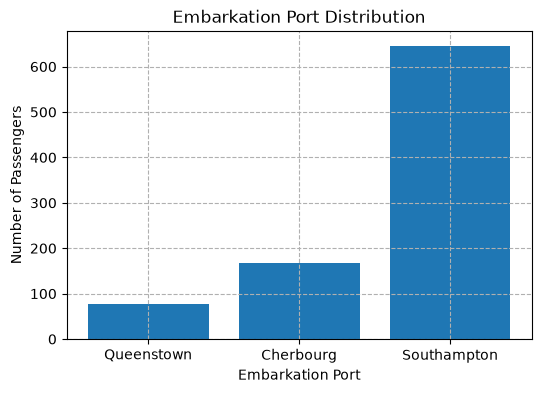

In [255]:
plt.figure(figsize = (6, 4))
plt.bar([port_names[x] for x in embarked_counts.index], embarked_counts.values)

plt.title("Embarkation Port Distribution")
plt.xlabel("Embarkation Port")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Most passengers embarked from `Southampton`, while `Cherbourg` and `Queenstown` contributed smaller groups.

## 2.10 NUMBER OF SIBLINGS AND SPOUSES (`sibsp`)

In [256]:
sibsp_counts = df_clean["sibsp"].value_counts().sort_index()
print(sibsp_counts)

sibsp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64


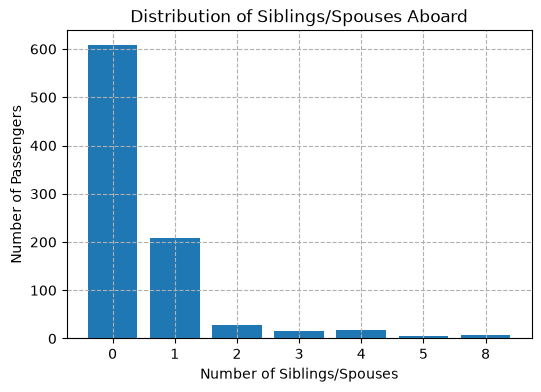

In [257]:
plt.figure(figsize = (6, 4))

plt.bar(sibsp_counts.index.astype(str), sibsp_counts.values)

plt.title("Distribution of Siblings/Spouses Aboard")
plt.xlabel("Number of Siblings/Spouses")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Most passengers travelled without siblings or spouses aboard. A smaller number of passengers travelled with one or more siblings or spouses. 

## 2.11 NUMBER OF PARENTS AND CHILDREN (`parch`)

The `parch` feature represents the number of parents or children accompanying each passenger.

We examine its distribution to understand the family structure of passengers.

In [258]:
parch_counts = df_clean["parch"].value_counts().sort_index()
print(parch_counts)

parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64


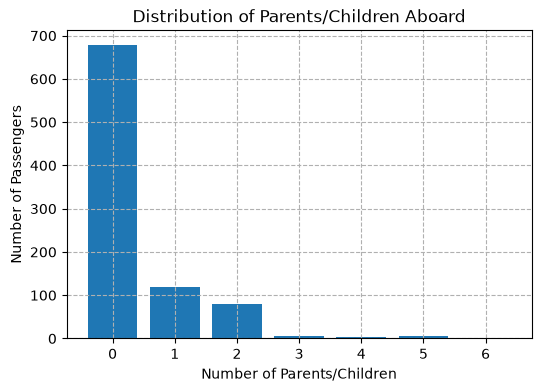

In [259]:
plt.figure(figsize = (6, 4))

plt.bar(parch_counts.index.astype(str), parch_counts.values)

plt.title("Distribution of Parents/Children Aboard")
plt.xlabel("Number of Parents/Children")
plt.ylabel("Number of Passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Most passengers travelled without parents or children aboard. A smaller number of passengers travelled with one or more parents or children. 

## 2.12 BOXPLOT ANALYSIS

Boxplots are used to examine the spread and possible outliers in numerical features.

We will analyze:
- `Age`

- `Fare`

The boxplot helps identify the median, quartiles, overall spread, and potential extreme values.

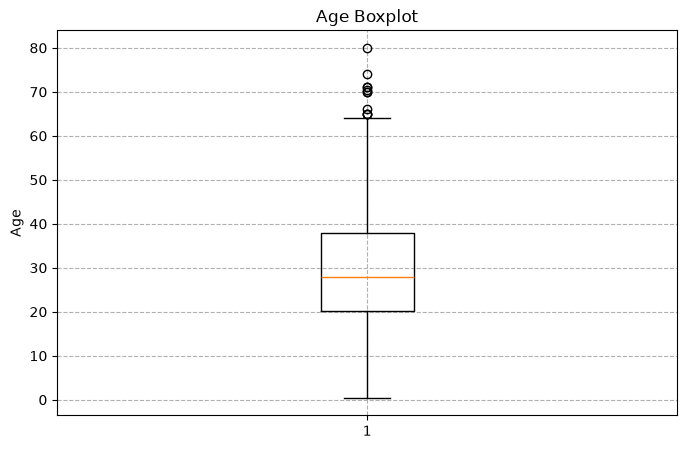

In [260]:
plt.figure(figsize = (8, 5))

plt.boxplot(df_clean["age"].dropna())

plt.title("Age Boxplot")
plt.ylabel("Age")

plt.grid(linestyle = "--")
plt.show()

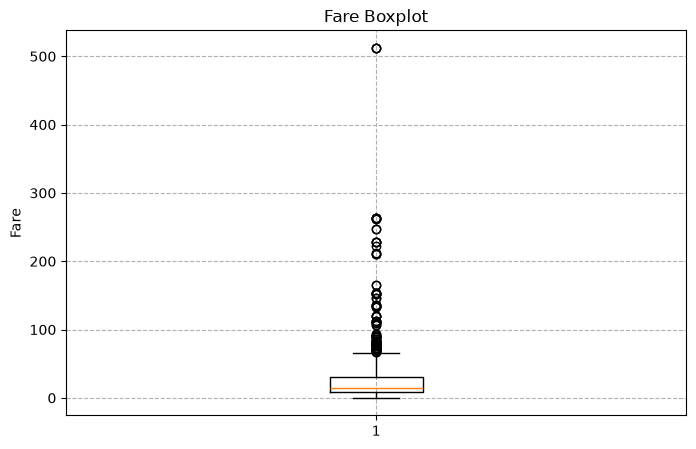

In [261]:
plt.figure(figsize = (8, 5))

plt.boxplot(df_clean["fare"].dropna())

plt.title("Fare Boxplot")
plt.ylabel("Fare")

plt.grid(linestyle = "--")
plt.show()

## 2.13 TRAVELLING ALONE

The `alone` feature indicates whether the passenger was travelling alone.
This provides another view of the passenger's family/travel structure.

In [262]:
alone_counts = df_clean["alone"].value_counts()
print(alone_counts)

alone
True     537
False    354
Name: count, dtype: int64


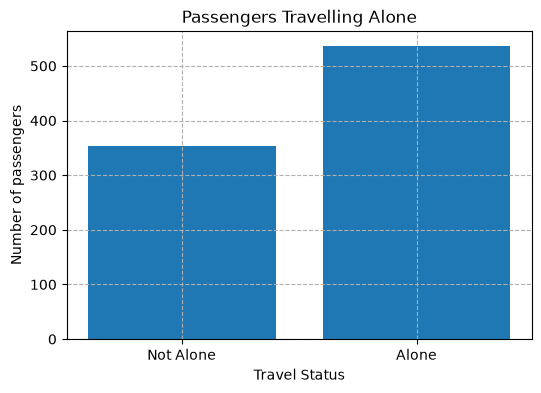

In [263]:
plt.figure(figsize = (6, 4))

plt.bar(["Not Alone", "Alone"], [alone_counts.get(False, 0), alone_counts.get(True, 0)])

plt.title("Passengers Travelling Alone")
plt.xlabel("Travel Status")
plt.ylabel("Number of passengers")

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

A considerable portion of passengers were travelling alone, while the remaining passengers had at least one family member or spouse/sibling travelling with them. 

# PART 2 SUMMARY

The major observations from the univariate analysis are:

1. The number of non-survivors is higher than the number of survivors.

2. The passenger dataset contains more male passengers than female passengers.

3. Third-class passengers form the largest passenger class.

4. Passenger ages cover a wide range, with most passengers concentrated around young and middle adulthood.

5. Fare values are strongly right-skewed, with a small number of passengers paying very high fares.

6. Most passengers embarked from Southampton.

7. Most passengers had no siblings or spouses aboard.

8. Most passengers had no parents or children aboard.

9.  Fare contains several potential high-value outliers, while age also contains some extreme observations.

10. A substantial portion of passengers were travelling alone.

# PART 3: BIVARIATE AND MULTIVARIATE ANALYSIS

## 3.1 INTRODUCTION

In this section, we study the relationship between two or more features.

The main objective is to understand which passenger characteristics are associated with survival and whether these patterns change when multiple factors are considered together.

We will use:
- `groupby()`

- `agg()`

- `crosstab()`

- `corr()`

Suitable visualizations such as bar charts, grouped bar charts, scatter plots, boxplots, and heatmaps will be used to support the analysis.

Correlation and association observed in this analysis do not necessarily imply causation.


## 3.2 GENDER VS SURVIVAL

The survival rate is calculated as the mean of the `survived` column because:

- `0` represents non-survival

- `1` represents survival

Therefore, the mean of `survived` represents the proportion of passengers who survived.

In [264]:
gender_analysis = df_clean.groupby("sex").agg(
    Passenger_Count = ("survived", "count"), 
    Survivors = ("survived", "sum"), 
    Survival_Rate = ("survived", "mean")
)
gender_analysis["Survival_Rate"] *= 100

gender_analysis

,Passenger_Count,Survivors,Survival_Rate
sex,,,
female,314,233,74.203822
male,577,109,18.890815


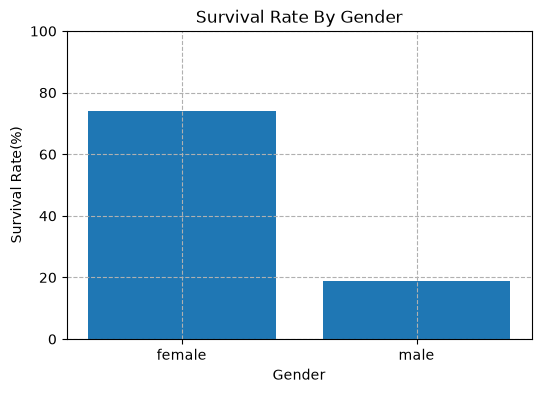

In [265]:
plt.figure(figsize = (6, 4))

plt.bar(gender_analysis.index, gender_analysis["Survival_Rate"])

plt.title("Survival Rate By Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Female passengers had a substantially higher survival rate than the male passengers in the dataset.

Therefore, gender shows a strong association with survival.


## 3.3 PASSENGER CLASS VS SURVIVAL

We analyze survival rates across the three passenger classes.

This helps us determine whether passenger class was associated with survival.

In [266]:
class_analysis = df_clean.groupby("pclass").agg(
    Passenger_Count = ("survived", "count"), 
    Survivors = ("survived", "sum"), 
    Survival_Rate = ("survived", "mean")
)
class_analysis["Survival_Rate"] *= 100

class_analysis

,Passenger_Count,Survivors,Survival_Rate
pclass,,,
1,216,136,62.962963
2,184,87,47.282609
3,491,119,24.236253


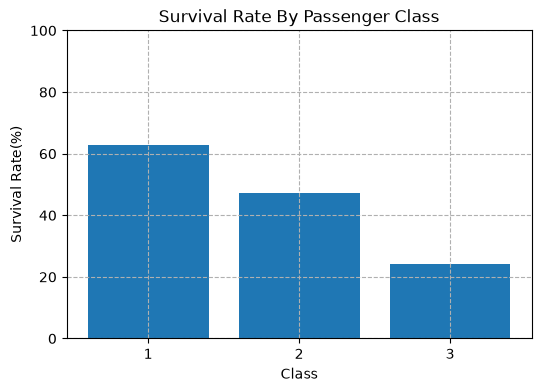

In [267]:
plt.figure(figsize = (6, 4))

plt.bar(class_analysis.index.astype(str), class_analysis["Survival_Rate"])

plt.title("Survival Rate By Passenger Class")
plt.xlabel("Class")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

First-class passengers had the highest survival rate, while third-class passengers had the lowest survival rate.

Passenger class therefore shows a strong association with survival.

## 3.4 AGE VS SURVIVAL

Age is a continuous numerical feature.

To study its relationship with survival, we divide passengers into age groups and calculate the survival rate for each group.

This helps us identify whether survival patterns differ across age ranges.

In [268]:
age_groups = pd.cut(
    df_clean["age"], bins = [0, 12, 18, 30, 45, 60, 100], 

        labels=[
        "Child",
        "Teenager",
        "Young Adult",
        "Adult",
        "Middle Age",
        "Senior"
    ]
)

age_survival = df_clean.groupby(age_groups, observed=False)["survived"].mean() * 100
age_survival

age
Child          57.971014
Teenager       42.857143
Young Adult    35.555556
Adult          42.574257
Middle Age     40.740741
Senior         22.727273
Name: survived, dtype: float64

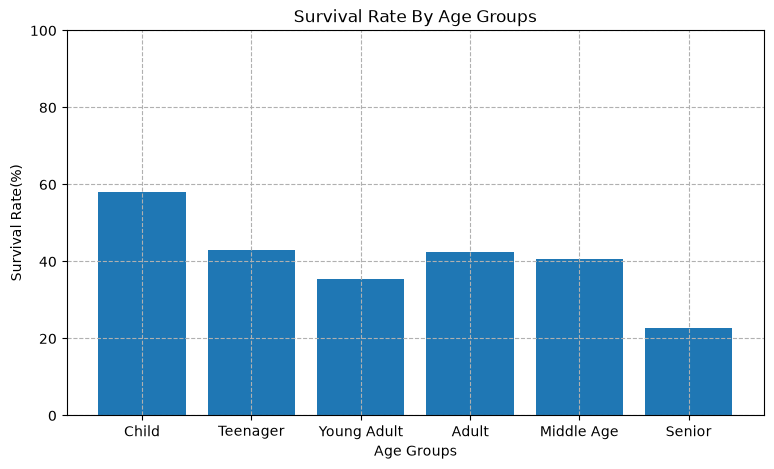

In [269]:
plt.figure(figsize = (9, 5))

plt.bar(age_survival.index, age_survival.values)
plt.title("Survival Rate By Age Groups")
plt.xlabel("Age Groups")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Survival rates vary across age groups. Children show a different survival pattern compared with several adult age groups.

However, age alone does not explain survival completely, so its interaction with other features will be examined later.

## 3.5 FARE VS SURVIVAL

We examine whether survival rates differ across fare ranges.

Since fare is a continuous variable and has a highly skewed distribution, we divide it into ranges before comparing survival rates.

In [270]:
fare_groups = pd.qcut(df_clean["fare"], q = 4, duplicates = "drop")

fare_survival = df_clean.groupby(fare_groups, observed = False)["survived"].mean()*100

fare_survival

fare
(-0.001, 7.91]     19.730942
(7.91, 14.454]     30.357143
(14.454, 31.0]     45.495495
(31.0, 512.329]    58.108108
Name: survived, dtype: float64

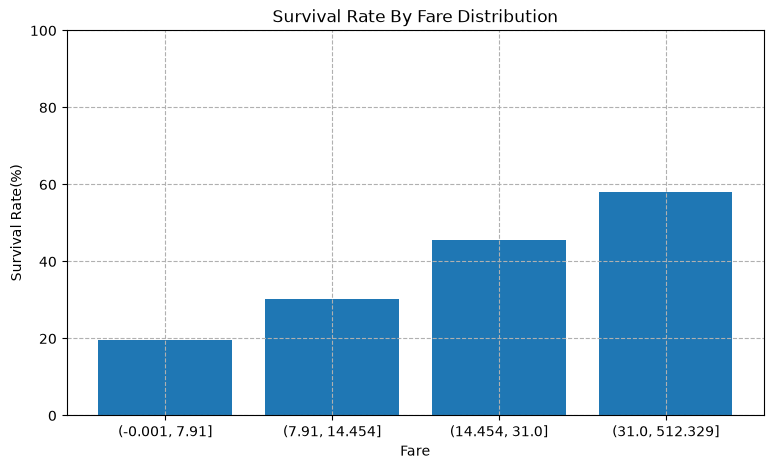

In [271]:
plt.figure(figsize = (9, 5))

plt.bar(fare_survival.index.astype(str), fare_survival.values)

plt.title("Survival Rate By Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Passengers in higher fare groups show higher survival rates than passengers in the lowest fare groups.

This suggests an association between fare and survival, although fare may also reflect differences in passenger class.

## 3.6 EMBARKATION PORT VS SURVIVAL

We compare survival rates across the three embarkation ports.

This helps us determine whether survival patterns differed according to the passenger's port of embarkation.

In [272]:
embarked_survival = df_clean.groupby("embarked")["survived"].mean()*100
port_names = {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}

embarked_survival

embarked
C    55.357143
Q    38.961039
S    33.900929
Name: survived, dtype: float64

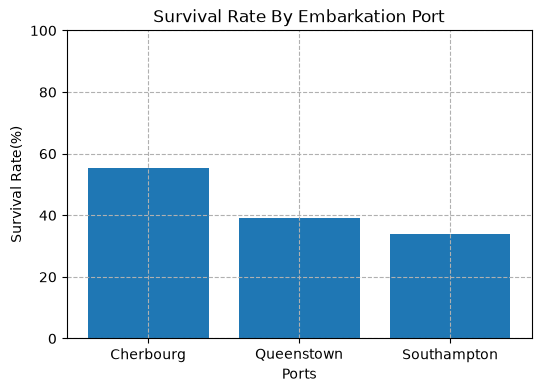

In [273]:
plt.figure(figsize = (6, 4))

plt.bar([port_names[x] for x in embarked_survival.index], embarked_survival.values)

plt.title("Survival Rate By Embarkation Port")
plt.xlabel("Ports")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Survival rates differ across embarkation ports. However, this difference may partially reflect other passenger characteristics such as passenger class and gender.

## 3.7 NUMBER OF SIBLINGS/SPOUSES VS SURVIVAL

We examine whether survival rates vary with the number of siblings or spouses travelling with a passenger.

The `sibsp` feature represents the number of siblings or spouses aboard.

In [274]:
sibsp_survival = df_clean.groupby("sibsp")["survived"].agg(["count", "mean"])
sibsp_survival["mean"] *= 100

sibsp_survival.rename (
    columns = {"count" : "Passenger_Count", "mean" : "Survival_Rate"}, inplace = True
)
sibsp_survival

,Passenger_Count,Survival_Rate
sibsp,,
0,608,34.539474
1,209,53.588517
2,28,46.428571
3,16,25.000000
4,18,16.666667
5,5,0.000000
8,7,0.000000


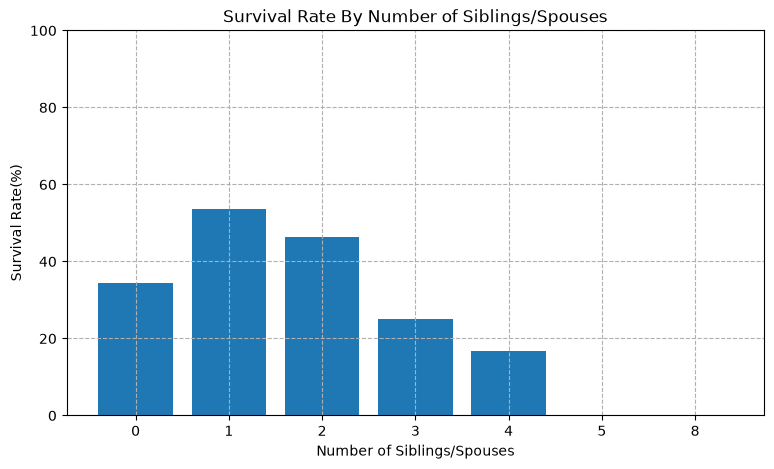

In [275]:
plt.figure(figsize = (9, 5))

plt.bar(sibsp_survival.index.astype(str), sibsp_survival["Survival_Rate"])

plt.title("Survival Rate By Number of Siblings/Spouses")
plt.xlabel("Number of Siblings/Spouses")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### Observation

Survival rates vary with the number of siblings or spouses aboard. 

Passengers travelling with a small number of family members show different survival patterns compared with passengers travelling alone or in larger groups.

## 3.8 NUMBER OF PARENTS/CHILDREN VS SURVIVAL

We examine whether survival rates vary according to the number of parents or children travelling with a passenger.

In [276]:
parch_survival = df_clean.groupby("parch")["survived"].agg(["count", "mean"])
parch_survival["mean"] *= 100

parch_survival.rename (
    columns = {"count" : "Passenger_Count", "mean" : "Survival_Rate"}, inplace = True
)
parch_survival

,Passenger_Count,Survival_Rate
parch,,
0,678,34.365782
1,118,55.084746
2,80,50.000000
3,5,60.000000
4,4,0.000000
5,5,20.000000
6,1,0.000000


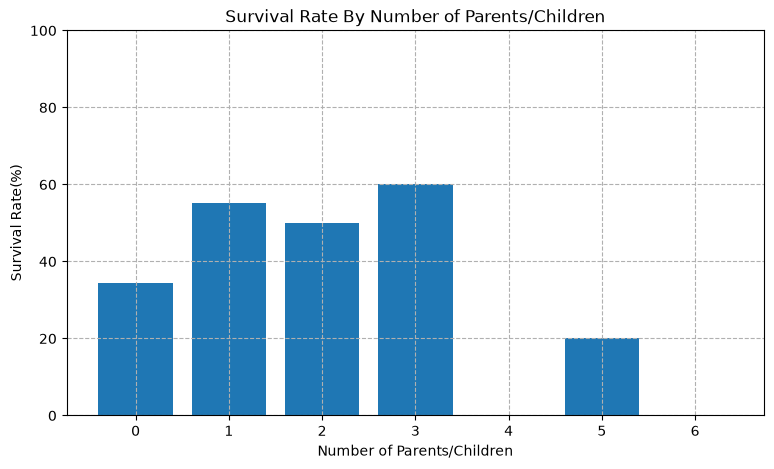

In [277]:
plt.figure(figsize = (9, 5))

plt.bar(parch_survival.index.astype(str), parch_survival["Survival_Rate"])

plt.title("Survival Rate By Number of Parents/Children")
plt.xlabel("Number of Parents/Children")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Survival rates vary with the number of parents or children aboard. 

The relationship is not necessarily linear, indicating that family size alone does not completely determine survival.

## 3.9 CHILDREN VS ADULTS

We compare survival rates between children and adults.

For this analysis:
- Age below 18 is classified as a child.
- Age 18 or above is classified as an adult.

Passengers with missing age are excluded from this specific comparison.

In [278]:
child_adult = df_clean[df_clean["age"].notna()].copy()

child_adult["age_group"] = np.where(child_adult["age"] < 18, "Child", "Adult")

child_adult_analysis = child_adult.groupby(
    "age_group"
).agg(
    Passenger_Count=("survived", "count"),
    Survivors=("survived", "sum"),
    Survival_Rate=("survived", "mean")
)

child_adult_analysis["Survival_Rate"] *= 100

child_adult_analysis


,Passenger_Count,Survivors,Survival_Rate
age_group,,,
Adult,601,229,38.103161
Child,113,61,53.982301


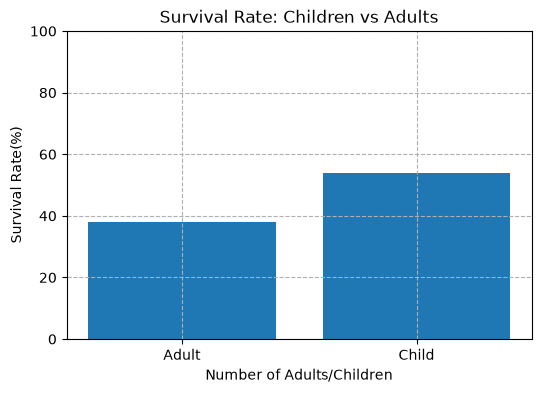

In [279]:
plt.figure(figsize = (6, 4))

plt.bar(child_adult_analysis.index, child_adult_analysis["Survival_Rate"])

plt.title("Survival Rate: Children vs Adults")
plt.xlabel("Number of Adults/Children")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION 

Children and adults show different survival rates in the dataset.

This indicates that age group is associated with survival, although the observed pattern can also be influenced by other factors such as gender and passenger class.

## 3.10 GENDER AND PASSENGER CLASS VS SURVIVAL

We now analyze gender and passenger class together.

This helps us determine whether the relationship between gender and survival rate remains similar across different passenger classes.

In [280]:
gender_class_table = df_clean.groupby(["pclass", "sex"])["survived"].mean().unstack() * 100

gender_class_table

sex,female,male
pclass,,
1,96.808511,36.885246
2,92.105263,15.740741
3,50.000000,13.544669


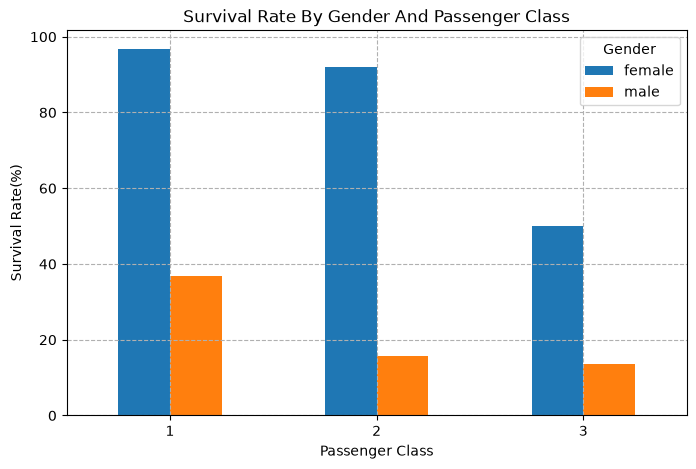

In [281]:
gender_class_table.plot(kind = "bar", figsize = (8, 5))

plt.title("Survival Rate By Gender And Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate(%)")

plt.xticks(rotation = 0)
plt.legend(title = "Gender")
plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Gender differences in survival can be observed across passenger classes. Female passengers generally have higher survival rates than male passengers within the same class.

Passenger class also influences the overall survival pattern, showing that survival is better understood when gender and class are considered together.

## 3.11 AGE AND GENDER VS SURVIVAL

We analyze age groups and gender together to determine whether survival patterns differ between males and females across different age groups.

In [282]:
age_gender_data = df_clean[df_clean["age"].notna()].copy()

age_gender_data["age_group"] = pd.cut(
    age_gender_data["age"], bins = [0, 12, 18, 30, 45, 60, 100], 
    labels = ["Child", "Teenager", "Young Adult", "Adult", "Middle Age", "Senior"]
)

age_gender_survival = age_gender_data.groupby(["age_group", "sex"], observed = False)["survived"].mean().unstack()*100

age_gender_survival

sex,female,male
age_group,,
Child,59.375000,56.756757
Teenager,75.000000,8.823529
Young Adult,75.555556,15.555556
Adult,78.082192,22.480620
Middle Age,85.185185,18.518519
Senior,100.000000,10.526316


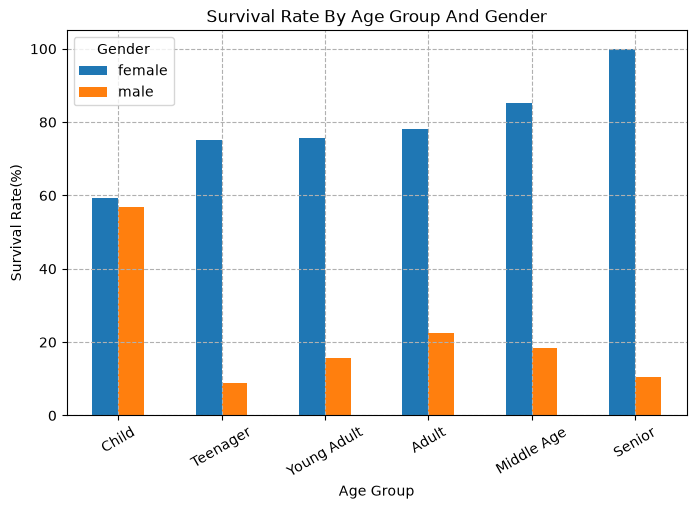

In [283]:
age_gender_survival.plot(kind = "bar", figsize = (8, 5))

plt.title("Survival Rate By Age Group And Gender")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate(%)")

plt.xticks(rotation = 30)
plt.legend(title = "Gender")
plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Survival patterns vary across age groups and gender.

Considering age and gender together provides more detailed information than examining either feature independently.

## 3.12 CROSS-TABULATION OF GENDER AND SURVIVAL

We use `pd.crosstab()` to examine the number of survivors and non-survivors within each gender category.

In [284]:
gender_survival_percentage = pd.crosstab(df_clean["sex"], df_clean["survived"], normalize="index") * 100

gender_survival_percentage

survived,0,1
sex,,
female,25.796178,74.203822
male,81.109185,18.890815


## 3.13 CORRELATION ANALYSIS

Correlation measures the strength and direction of a linear relationship between numerical variables.

We examine the relationship between survival and numerical features such as:
- Passenger class
- Age
- SibSp
- Parch
- Fare

A correlation value close to:
- `+1` indicates a strong positive relationship

- `-1` indicates a strong negative relationship

- `0` indicates little or no linear relationship

Correlation does not imply causation.

In [285]:
correlation_column = [
    "survived", 
    "pclass", 
    "sibsp", 
    "parch", 
    "fare", 
    "age"
]

correlation_matrix = df_clean[correlation_column].corr()

correlation_matrix

,survived,pclass,sibsp,parch,fare,age
survived,1.000000,-0.338481,-0.035322,0.081629,0.257307,-0.077221
pclass,-0.338481,1.000000,0.083081,0.018443,-0.549500,-0.369226
sibsp,-0.035322,0.083081,1.000000,0.414838,0.159651,-0.308247
parch,0.081629,0.018443,0.414838,1.000000,0.216225,-0.189119
fare,0.257307,-0.549500,0.159651,0.216225,1.000000,0.096067
age,-0.077221,-0.369226,-0.308247,-0.189119,0.096067,1.000000


In [286]:
survival_correlation = correlation_matrix["survived"].sort_values(ascending = False)

survival_correlation

survived    1.000000
fare        0.257307
parch       0.081629
sibsp      -0.035322
age        -0.077221
pclass     -0.338481
Name: survived, dtype: float64

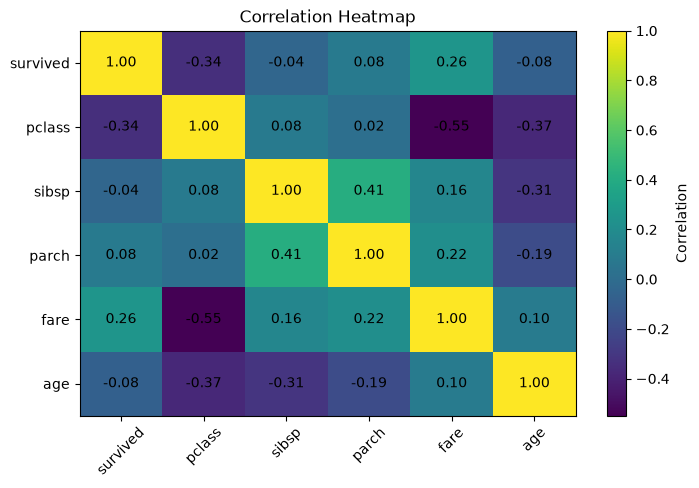

In [309]:
plt.figure(figsize = (8, 5))

plt.imshow(correlation_matrix, aspect = "auto")

plt.colorbar(label = "Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation = 45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i, f"{correlation_matrix.iloc[i, j]:.2f}", 
            ha = "center", va = "center"
        )

plt.title("Correlation Heatmap")
plt.show()

# PART 3: SUMMARY

The major findings from the analysis are:

1. Gender shows a strong association with survival, with female passengers having a substantially higher survival rate than male passengers.

2. Passenger class is strongly associated with survival. First-class passengers have higher survival rates than second- and third-class passengers.

3. Survival rates vary across age groups, indicating that age is associated with survival.

4. Higher fare groups generally show higher survival rates. This relationship may partly reflect the relationship between fare and passenger class.

5. Survival rates differ across embarkation ports, although this pattern may also be influenced by other passenger characteristics.

6. The number of siblings/spouses and parents/children is associated with different survival patterns, but the relationship is not simply linear.

7. Children and adults show different survival patterns.

8. When gender and passenger class are analyzed together, gender differences remain visible across classes, showing that multiple passenger characteristics jointly describe survival patterns.

9. Combining age and gender provides more detailed survival patterns than analyzing either feature independently.

10. Correlation analysis shows associations between survival and several numerical features, but correlation alone cannot establish causation.

Overall, gender and passenger class appear to be among the strongest individual characteristics associated with survival in this dataset, while the combined analysis shows that survival patterns can change when multiple factors are considered together.

# PART 4: FEATURE ENGINEERING, INSIGHTS AND FINAL REPORT



## 4.1 INTRODUCTION

In this section, we create useful derived features from the existing Titanic dataset and use them to perform additional analysis.

The main objectives are:

- Create a `FamilySize` feature using `SibSp` and `Parch`.
- Compare solo travellers with passengers travelling with family members.
- Create meaningful family-size and age-group categories.
- Analyze engineered features with respect to survival.
- Review important numerical relationships.
- Identify the strongest findings from the complete EDA.
- Discuss missing data and limitations of the dataset.
- Summarize the complete project in a final conclusion.

Note: The dataset used in this project does not contain passenger names, so title extraction such as Mr, Mrs, Miss, or Master is not performed.

## 4.2 CREATING FINAL ANALYSIS DATASET

In [288]:
final_df = df_clean.copy()
print("Final Analysis Dataset Created Successfully!!!")
print("Rows: ", final_df.shape[0])
print("Columns: ", final_df.shape[1])

Final Analysis Dataset Created Successfully!!!
Rows:  891
Columns:  15


## 4.3 CREATING THE FamilySize FEATURE

The original dataset contains two family-related features: 

- `sibsp`: number of siblings/spouses aboard

- `parch`: number of parents/children aboard

We combine these features and add 1 for the passenger themselves to create a new feature:

`FamilySize = SibSp + Parch + 1`

This provides a single measure of the total family size travelling with the passenger.

In [289]:
final_df["FamilySize"] = (final_df["sibsp"] + final_df["parch"] + 1)

final_df[["sibsp", "parch", "FamilySize"]].head(10)

,sibsp,parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


## 4.4 CHECK FamilySize

In [290]:
print("Minimum FamilySize: ", final_df["FamilySize"].min())
print("Maximum FamilySize: ", final_df["FamilySize"].max())

Minimum FamilySize:  1
Maximum FamilySize:  11


In [291]:
final_df["FamilySize"].value_counts().sort_index()

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

## 4.5 SOLO TRAVELLERS VS FAMILY TRAVELLERS

Using `FamilySize`, passengers are divided into two groups: 

- `Solo` — passenger travelled alone.

- `With Family` — passenger travelled with at least one family member.

We then compare their survival rates.

In [292]:
final_df["TravelType"] = np.where(final_df["FamilySize"] == 1, "Solo", "With Family")
final_df["TravelType"].value_counts()

TravelType
Solo           537
With Family    354
Name: count, dtype: int64

## 4.6 TRAVELTYPE VS SURVIVAL

In [293]:
traveltype_analysis = final_df.groupby("TravelType").agg(
    Passenger_Count = ("survived", "count"), 
    Survivors = ("survived", "sum"), 
    Survival_Rate = ("survived", "mean")
)

traveltype_analysis["Survival_Rate"] *= 100

traveltype_analysis

,Passenger_Count,Survivors,Survival_Rate
TravelType,,,
Solo,537,163,30.353818
With Family,354,179,50.564972


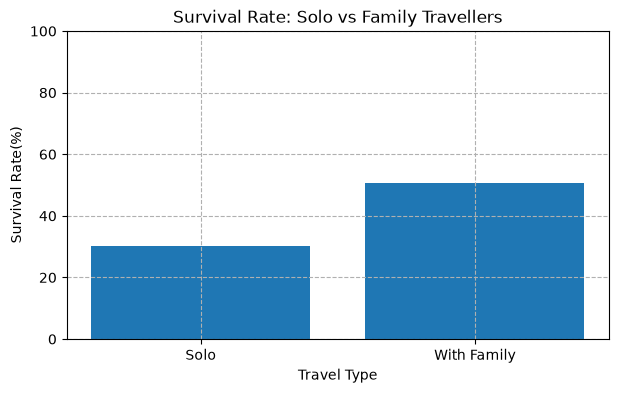

In [294]:
plt.figure(figsize = (7, 4))

plt.bar(traveltype_analysis.index, traveltype_analysis["Survival_Rate"])

plt.title("Survival Rate: Solo vs Family Travellers")
plt.xlabel("Travel Type")
plt.ylabel("Survival Rate(%)")

plt.ylim(0, 100)
plt.grid(linestyle = "--")
plt.show()

### OBSERVATION

Survival rates differ between solo travellers and passengers travelling with family members.

This suggests that family travel status is associated with survival, although the relationship may also be influenced by factors such as gender, age, and passenger class.

## 4.7 CREATING FAMILY SIZE CATEGORIES

The exact `FamilySize` value can contain many different values.

To make the analysis easier to interpret, passengers are grouped into four categories:

- `Solo`

- `Small Family` — 2 to 4 members

- `Medium Family` — 5 to 6 members

- `Large Family` — 7 or more members

In [295]:
def categorize_family_size(size):
    if size == 1:
        return "Solo"
    elif size <= 4:
        return "Small Family"
    elif size <= 6:
        return "Medium Family"
    else:
        return "Large Family"

final_df["FamilyType"] = final_df["FamilySize"].apply(categorize_family_size)
final_df["FamilyType"].value_counts()

FamilyType
Solo             537
Small Family     292
Medium Family     37
Large Family      25
Name: count, dtype: int64

## 4.8 FAMILY TYPE VS SURVIVAL

In [296]:
familytype_analysis = final_df.groupby("FamilyType").agg(
    Passenger_Count = ("survived", "count"), 
    Survivors = ("survived", "sum"), 
    Survival_Rate = ("survived", "mean")
)

familytype_analysis["Survival_Rate"] *= 100
familytype_analysis

,Passenger_Count,Survivors,Survival_Rate
FamilyType,,,
Large Family,25,4,16.000000
Medium Family,37,6,16.216216
Small Family,292,169,57.876712
Solo,537,163,30.353818


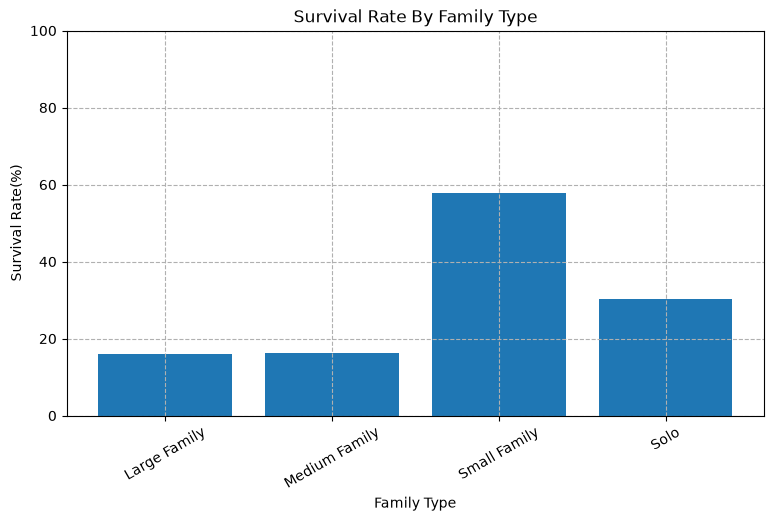

In [297]:
plt.figure(figsize = (9, 5))

plt.bar(familytype_analysis.index, familytype_analysis["Survival_Rate"])

plt.title("Survival Rate By Family Type")
plt.xlabel("Family Type")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.xticks(rotation = 30)
plt.grid(linestyle = "--")
plt.show()


### OBSERVATION

Survival rates vary across different family-size categories.

Passengers travelling in smaller family groups may show different survival patterns compared with solo travellers or passengers in very large families.

The relationship is not necessarily linear, showing that family size alone does not determine survival.

## 4.9 CREATING AGE GROUP FEATURE 

Age is a continuous variable, so we create meaningful age categories to simplify interpretation.

The categories used are:

- Child
- Teenager
- Young Adult
- Adult
- Middle Age
- Senior

Passengers with missing age remain missing in this feature.

In [298]:
final_df["AgeGroup"] = pd.cut(
    final_df["age"], 
    bins = [0, 12, 18, 30, 45, 60, 100],
        labels=[
        "Child",
        "Teenager",
        "Young Adult",
        "Adult",
        "Middle Age",
        "Senior"
    ], include_lowest = True
)

final_df["AgeGroup"].value_counts().sort_index()

AgeGroup
Child           69
Teenager        70
Young Adult    270
Adult          202
Middle Age      81
Senior          22
Name: count, dtype: int64

## 4.10 AGE GROUP VS SURVIVAL



In [299]:
agegroup_analysis = final_df.groupby("AgeGroup", observed = False).agg(
    Passenger_Count = ("survived", "count"), 
    Survivors = ("survived", "sum"), 
    Survival_Rate = ("survived", "mean")
)

agegroup_analysis["Survival_Rate"] *= 100
agegroup_analysis


,Passenger_Count,Survivors,Survival_Rate
AgeGroup,,,
Child,69,40,57.971014
Teenager,70,30,42.857143
Young Adult,270,96,35.555556
Adult,202,86,42.574257
Middle Age,81,33,40.740741
Senior,22,5,22.727273


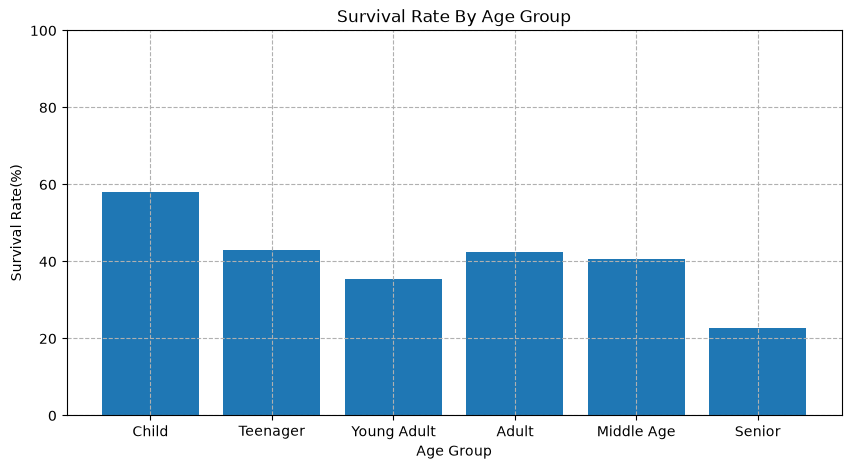

In [311]:
plt.figure(figsize = (10, 5))
plt.bar(agegroup_analysis.index.astype(str), agegroup_analysis["Survival_Rate"])

plt.title("Survival Rate By Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate(%)")
plt.ylim(0, 100)

plt.grid(linestyle = "--")
plt.show()

### OBSERVATION 

The engineered `AgeGroup` feature makes age-related survival patterns easier to compare.

Different age groups show different survival rates, indicating that age is an important passenger characteristic associated with survival.

## 4.11 SUMMARY OF ENGINEERED FEATURES

The main engineered features created in this section are: 

- `FamilySize`

- `TravelType`

- `FamilyType`

- `AgeGroup`

These features transform the original variables into more interpretable representations that can be used for further analysis.

In [301]:
final_df[["sibsp", "parch", "FamilySize", "TravelType", "FamilyType", "age", "AgeGroup", "survived"]].head(10)

,sibsp,parch,FamilySize,TravelType,FamilyType,age,AgeGroup,survived
0,1,0,2,With Family,Small Family,22.0,Young Adult,0
1,1,0,2,With Family,Small Family,38.0,Adult,1
2,0,0,1,Solo,Solo,26.0,Young Adult,1
3,1,0,2,With Family,Small Family,35.0,Adult,1
4,0,0,1,Solo,Solo,35.0,Adult,0
5,0,0,1,Solo,Solo,NaN,NaN,0
6,0,0,1,Solo,Solo,54.0,Middle Age,0
7,3,1,5,With Family,Medium Family,2.0,Child,0
8,0,2,3,With Family,Small Family,27.0,Young Adult,1
9,1,0,2,With Family,Small Family,14.0,Teenager,1


## 4.12 ENGINEERED FEATURES VS SURVIVAL

In [312]:
print("TRAVEL TYPE VS SURVIVAL: ")
print(final_df.groupby("TravelType", observed = False)["survived"].mean()*100)

print("\nFAMILY TYPE VS SURVIVAL: ")
print(final_df.groupby("FamilyType", observed = False)["survived"].mean()*100)

print("\nAGE GROUP VS SURVIVAL: ")
print(final_df.groupby("AgeGroup", observed = False)["survived"].mean()*100)



TRAVEL TYPE VS SURVIVAL: 
TravelType
Solo           30.353818
With Family    50.564972
Name: survived, dtype: float64

FAMILY TYPE VS SURVIVAL: 
FamilyType
Large Family     16.000000
Medium Family    16.216216
Small Family     57.876712
Solo             30.353818
Name: survived, dtype: float64

AGE GROUP VS SURVIVAL: 
AgeGroup
Child          57.971014
Teenager       42.857143
Young Adult    35.555556
Adult          42.574257
Middle Age     40.740741
Senior         22.727273
Name: survived, dtype: float64


## 4.13 FINAL NUMERICAL CORRELATIONS

We now review numerical relationships after creating the `FamilySize` feature.

The analysis includes:

- `survived`

- `pclass`

- `age`

- `sibsp`

- `parch`

- `fare`

- `FamilySize`

Correlation measures association between numerical variables and does not imply causation.

In [303]:
final_numeric_columns = [
    "survived", 
    "pclass", 
    "age", 
    "sibsp" ,
    "parch", 
    "fare", 
    "FamilySize"
]

final_correlation = final_df[final_numeric_columns].corr()
final_correlation

,survived,pclass,age,sibsp,parch,fare,FamilySize
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,0.016639
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.065997
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,-0.301914
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,0.890712
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,0.783111
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,0.217138
FamilySize,0.016639,0.065997,-0.301914,0.890712,0.783111,0.217138,1.000000


## 4.14 SURVIVAL CORRELATIONS

In [304]:
final_survival_correlations = (
    final_correlation["survived"].sort_values(ascending = False)
)

final_survival_correlations

survived      1.000000
fare          0.257307
parch         0.081629
FamilySize    0.016639
sibsp        -0.035322
age          -0.077221
pclass       -0.338481
Name: survived, dtype: float64

## 4.15 FINAL CORRELATION HEATMAP

The final correlation matrix is visualized as a heatmap to make important numerical relationships easier to identify.

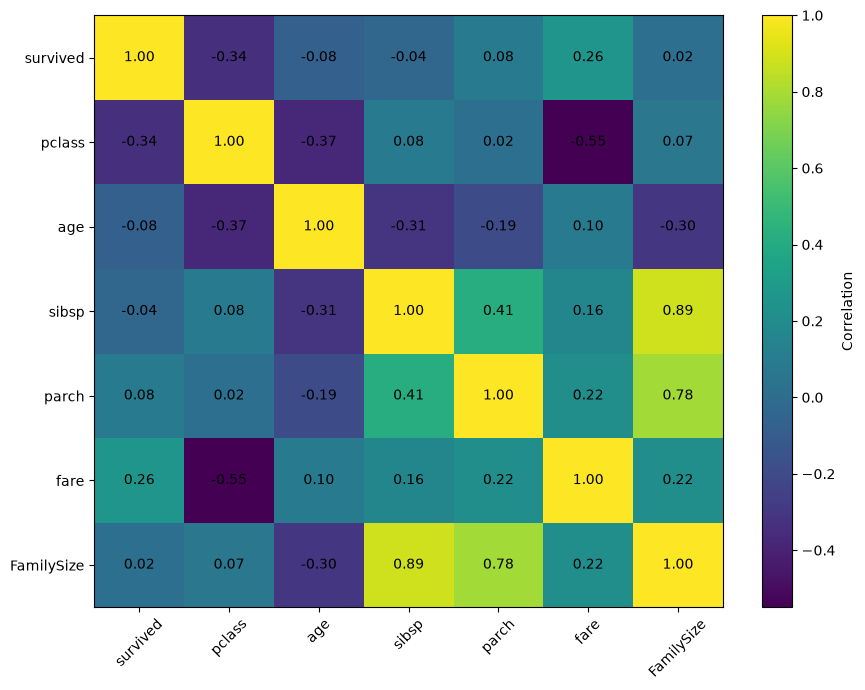

In [308]:
plt.figure(figsize = (9, 7))

plt.imshow(final_correlation, aspect = "auto")
plt.colorbar(label = "Correlation")

plt.xticks(range(len(final_correlation.columns)), final_correlation.columns, rotation = 45)
plt.yticks(range(len(final_correlation.columns)), final_correlation.columns)

for i in range(len(final_correlation.columns)):
    for j in range(len(final_correlation.columns)):
        plt.text(
            j, 
            i, 
            f"{final_correlation.iloc[i, j]:.2f}", 
            ha = "center", 
            va = "center"
        )

plt.tight_layout()
plt.show()

## 4.16 FINAL DATASET CHECK

Before concluding the project, we verify the final dataset structure and confirm that the engineered features have been added successfully. 

In [306]:
print("FINAL DATASET SHAPE: ", final_df.shape)

print("\n FINAL COLUMNS: ")
print(final_df.columns.tolist())

FINAL DATASET SHAPE:  (891, 19)

 FINAL COLUMNS: 
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone', 'FamilySize', 'TravelType', 'FamilyType', 'AgeGroup']


## 4.17 MISSING DATA AND DATASET LIMITATIONS

The dataset contains missing values, especially in the `age` and `deck` features.

Missing values can affect analyses that depend on those columns.

The `deck` feature contains a large amount of missing information, so conclusions involving deck should be interpreted cautiously.

The dataset also does not contain passenger names, ticket numbers, or passenger IDs. Therefore, name-based title extraction, ticket-group analysis, and passenger-level identification are not possible with this version of the dataset.

In [307]:
final_missing = final_df.isnull().sum()
final_missing[final_missing > 0]

age         177
deck        688
AgeGroup    177
dtype: int64

## 4.18 LIMITATIONS OF THE ANALYSIS

The main limitations of the analysis are: 

1. The dataset contains missing values, especially in `age` and `deck`.

2. The `deck` feature has a large proportion of missing values, which limits its usefulness for direct analysis.

3. The dataset does not contain passenger names, so title-based feature engineering could not be performed.

4. The dataset does not contain `PassengerId`, `Name`, or `Ticket`, limiting passenger-level identification and ticket-group analysis.

5. Some features are redundant or closely related. For example, `survived` and `alive` represent the same outcome, while `pclass` and `class` describe the same passenger-class information.

6. Correlation and group-level differences indicate association, not causation.

7. Observed survival patterns may be influenced by multiple interacting factors such as gender, age, passenger class, and family structure.

## 4.19 STRONGEST FINDINGS FROM THE COMPLETE EDA

Based on the analysis performed throughout the project, the strongest findings are: 

### 1. Gender and Survival

Female passengers had a substantially higher survival rate than male passengers.

This makes gender one of the strongest characteristics associated with survival in the dataset.

### 2. Passenger Class and Survival

First-class passengers had higher survival rates than second- and third-class passengers.

Passenger class therefore shows a strong association with survival.

### 3. Gender and Passenger Class Together

When gender and passenger class are analyzed together, survival patterns become more detailed.

Female passengers generally show higher survival rates within the same passenger class, while class also contributes to differences in survival.

### 4. Age and Survival

Different age groups show different survival patterns.

Children and adults do not have identical survival rates, indicating that age is an important factor to consider.

### 5. Fare and Survival

Passengers in higher fare groups generally show higher survival rates.

However, fare is related to passenger class, so this relationship should not be interpreted independently of class.

### 6. Family Structure and Survival

Family size and travel status show different survival patterns.

Solo travellers and passengers travelling with family members do not have identical survival rates.

### 7. Multiple Features Provide Better Understanding

The analysis shows that survival cannot be fully understood using a single feature.

Gender, passenger class, age, fare, and family structure can interact and produce different survival patterns.

### 8. Correlation Is Not Causation

The observed relationships describe associations within the dataset.

They do not prove that any individual characteristic directly caused a passenger to survive or not survive.

# 4.20 FINAL CONCLUSION 

This Titanic Exploratory Data Analysis examined the dataset from multiple perspectives, beginning with data understanding and cleaning, followed by univariate, bivariate, and multivariate analysis, along with feature engineering.

The analysis identified several important patterns associated with passenger survival.

Gender and passenger class showed particularly strong differences in survival rates. Age, fare, embarkation port, and family-related features also showed meaningful variations in survival.

Feature engineering allowed the original family-related variables to be combined into more interpretable features such as `FamilySize`, `TravelType`, and `FamilyType`. Age was also converted into meaningful age groups for easier comparison.

The multivariate analysis demonstrated that passenger survival is better understood by considering multiple characteristics together rather than relying on a single variable.

Overall, this project demonstrates a complete EDA workflow:

1. Understanding the dataset

2. Checking data quality

3. Exploring individual features

4. Studying relationships between features

5. Creating useful derived features

6. Supporting observations with numerical analysis and visualizations

7. Identifying meaningful patterns

8. Discussing limitations and avoiding unsupported causal conclusions

The findings provide a strong foundation for further statistical analysis or machine learning models using the Titanic dataset.

# TITANIC EDA — PROJECT SUMMARY

### Dataset
Titanic passenger dataset containing 891 passenger records and 15 original features.

### Main Analysis Areas

- Data understanding and cleaning
- Univariate analysis
- Bivariate analysis
- Multivariate analysis
- Feature engineering
- Survival analysis
- Correlation analysis

### Important Features Analyzed

- Gender
- Passenger class
- Age
- Fare
- Embarkation port
- SibSp
- Parch
- FamilySize
- TravelType
- FamilyType
- AgeGroup

### Main Finding

Gender and passenger class show particularly strong associations with survival, while age, fare, and family-related characteristics provide additional information when multiple factors are considered together.

### Important Limitation

The dataset does not contain passenger names, ticket numbers, or passenger IDs, and several columns contain missing values.

### Tools Used

- Python
- NumPy
- Pandas
- Matplotlib
- Jupyter Notebook